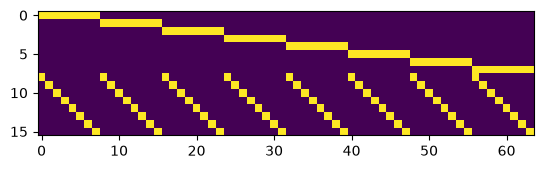

[0.  1.7 3.3 2.3 2.  2.4 1.4 0.  0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]
[0.  1.7 3.3 2.3 2.  2.4 1.4 0. ] [0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]


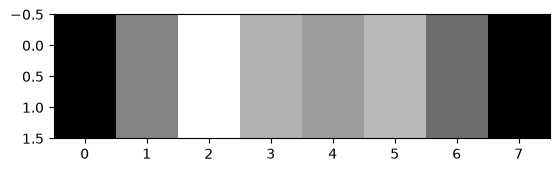

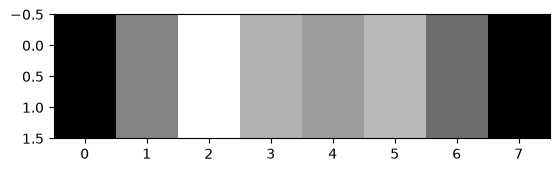

Dimensiones de A2:  (16, 64)
Dimensiones de A4:  (46, 64)
Dimensiones de A7:  (119, 64) 

Rango de A2:  15
Rango de A4:  39
Rango de A7:  64 

dim(Nul A2):  49
dim(Nul A4):  25
dim(Nul A7):  0 



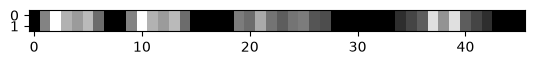

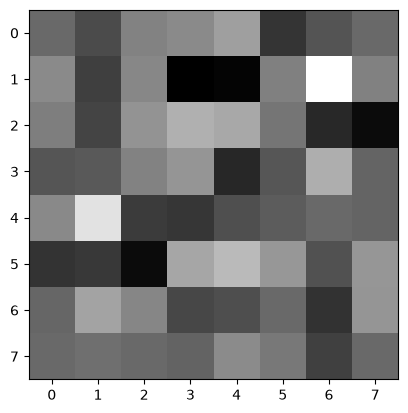

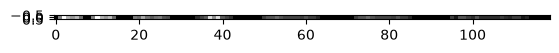

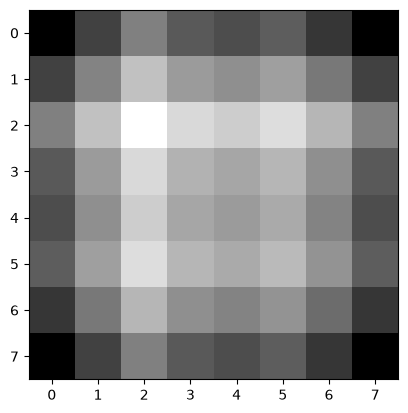

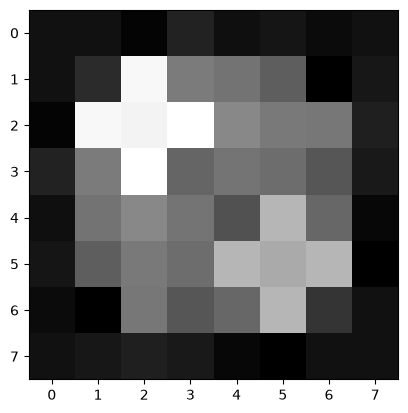

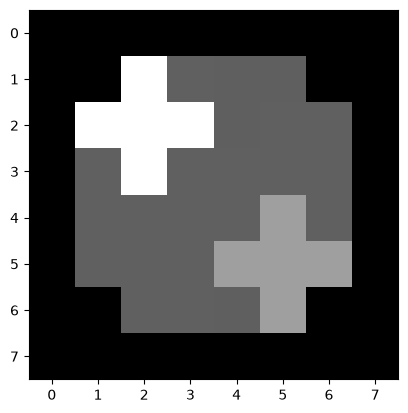

In [13]:
%run ejercicio_5.ipynb

# HERE IT BEGINS
Total el boludo despues corrige

In [ ]:
seed = 73

z = np.random.normal(loc=0.0, scale=1.0, size=119)
z

desvios = [0, 0.01, 0.03, 0.06, 0.1]

escala = np.sqrt(np.mean(b7**2))

ruidos = list()

for desvio in desvios:
    ruido = desvio * escala * z
    ruidos.append(ruido)

for i in range(len(ruidos)):
    print(ruidos[i])

[ 0. -0.  0.  0.  0. -0. -0. -0.  0. -0. -0.  0. -0.  0. -0.  0. -0. -0.
 -0. -0. -0. -0.  0. -0.  0.  0. -0.  0. -0.  0.  0. -0. -0.  0. -0. -0.
  0. -0.  0.  0.  0. -0. -0. -0. -0. -0. -0. -0. -0.  0.  0. -0. -0.  0.
 -0.  0. -0. -0. -0.  0.  0. -0. -0. -0.  0. -0. -0. -0.  0.  0. -0.  0.
  0. -0. -0.  0. -0. -0.  0.  0. -0. -0.  0.  0. -0.  0. -0. -0. -0.  0.
 -0.  0.  0.  0. -0.  0. -0.  0.  0. -0.  0.  0. -0.  0.  0. -0. -0. -0.
  0. -0.  0. -0.  0. -0. -0. -0.  0.  0. -0.]
[ 1.19286501e-02 -8.58278903e-03  1.83887881e-02  1.05884853e-03
  1.53358328e-02 -1.96535300e-02 -5.84788539e-03 -1.10244090e-03
  4.71424614e-03 -7.47405098e-03 -1.37132104e-02  1.88196019e-03
 -2.44040590e-02  1.97844098e-02 -1.35331629e-02  2.50523158e-03
 -2.13761456e-02 -1.37913515e-02 -2.05133053e-02 -1.27022200e-03
 -5.86247236e-03 -1.32835417e-02  6.56250490e-03 -1.52464086e-02
  2.88839258e-03  1.01106053e-02 -9.68340288e-03  5.13000193e-03
 -1.51418855e-03  6.88858216e-03  2.52604023e-03 -1.12743489e

In [ ]:
residuos_cuadrados = list()
mediciones_ruidosas = list()
reconstrucciones = list()

for i in range(len(desvios)):
    med_ruido = b7 + ruidos[i]
    mediciones_ruidosas.append(med_ruido)

    x_ruidoso = np.linalg.lstsq(A7, med_ruido)[0]
    reconstrucciones.append(x_ruidoso)

    residuos_cuadrados.append(np.linalg.norm(A7 @ x_ruidoso - med_ruido)**2)

for res_cuad in residuos_cuadrados:
    print(res_cuad)

2.5909380940421204e-28
0.007392729482608427
0.06653456534347582
0.2661382613739033
0.7392729482608421


In [24]:
errores_relativos_ruidos = list()
for i in range(len(reconstrucciones)):
    errores_relativos_ruidos.append(np.linalg.norm(reconstrucciones[i] - x_fantoma)/np.linalg.norm(x_fantoma))

In [25]:
tabla_sigma = pd.DataFrame({
    'residuo_cuadrado': [residuos_cuadrados[0], residuos_cuadrados[1], residuos_cuadrados[2]],
    'norma_ruido': [np.linalg.norm(ruidos[0]), np.linalg.norm(ruidos[1]), np.linalg.norm(ruidos[2])],
    'norma_residuo':  [np.sqrt(residuos_cuadrados[0]), np.sqrt(residuos_cuadrados[1]), np.sqrt(residuos_cuadrados[2])],
    'error_relativo': [errores_relativos_ruidos[0], errores_relativos_ruidos[1], errores_relativos_ruidos[2]],
    'max_aten': [np.max(reconstrucciones[0]), np.max(reconstrucciones[1]), np.max(reconstrucciones[2])],
    'min_aten': [np.min(reconstrucciones[0]), np.min(reconstrucciones[1]), np.min(reconstrucciones[2])]
})

tabla_sigma

,residuo_cuadrado,norma_ruido,norma_residuo,error_relativo,max_aten,min_aten
0,2.590938e-28,0.000000,1.609639e-14,2.328241e-15,0.800000,-1.776357e-15
1,7.392729e-03,0.125788,8.598098e-02,1.772637e-02,0.805706,-1.160932e-02
2,6.653457e-02,0.377364,2.579429e-01,5.317912e-02,0.817118,-3.482795e-02


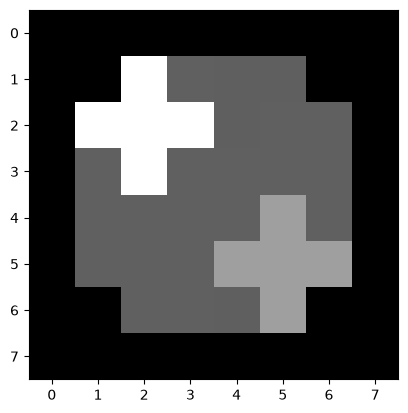

In [28]:
X_ruidoso_0 = reconstrucciones[0].reshape(8,8)

plt.imshow(X_ruidoso_0, cmap="gray")

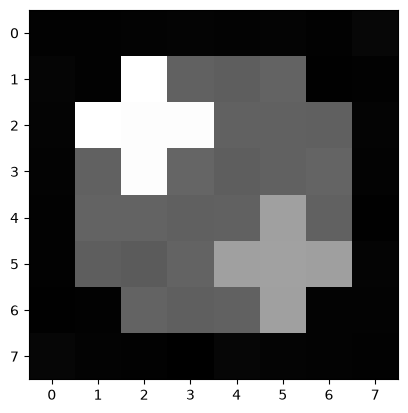

In [29]:
X_ruidoso_1 = reconstrucciones[1].reshape(8,8)

plt.imshow(X_ruidoso_1, cmap="gray")

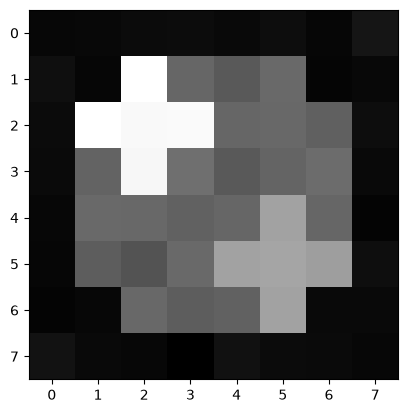

In [31]:
X_ruidoso_2 = reconstrucciones[2].reshape(8,8)

plt.imshow(X_ruidoso_2, cmap="gray")

Ahora se hace el seeeeeee (c)

Al aumentar $\sigma$, es decir, el ruido; el error de construcción $||x_{fantoma}\hat{x}_k||$ aumenta proporcionalmente.

La fórmula del residuo se puede reducir a la siguiente expresión:

$$r_{\sigma}=A_7(x_{fantoma}-\hat{x_\sigma})+\eta_\sigma$$

De esta manera, se puede observar que el residuo final no sólo es afectado por el error de reconstrucción, sino que también se ve directamente influido por el vector de ruidos. Así, la magnitud de los residuos es proporcional al nivel de ruido percibido.

Asimismo, la introducción de ruido en el problema puede ocasionar que algunas entradas de $b_\sigma$ sean negativas. En particular:

$$b_{\sigma,i} < 0 \iff b_{7,i} + \eta_{\sigma,i} < 0 \iff b_{7,i} < - \eta_{\sigma,i}$$

Si bien es improbable, esto podría llegar a ocurrir para alguna entrada. En consecuencia, para que $A_7\hat{x_\sigma} = b_\sigma$, la reconstrucción podría llegar a "exigir" que algún coeficiente de $\hat{x_\sigma}$ sea menor a cero para cumplir con el sistema.